# 10 · Independent validation against Canadian airborne lidar (NRCan CanElevation, 2019–2025)

**Question:** do the reclassified 30 m heights hold up across the **Canadian boreal**, from Yukon to Newfoundland, against
1 m airborne lidar flown in the same years as ICESat-2?

**Reference data:** NRCan's CanElevation HRDEM lidar collection (open, STAC: `datacube.services.geo.ca`): one item per
provincial / territorial / federal lidar project, each with a 1 m surface model (DSM, first returns) and terrain model
(DTM). **Canopy height = DSM − DTM**, the same 1 m canopy height model approach as the G-LiHT validation (notebook 05). The
files are cloud-optimised GeoTIFFs, so only the boxes we need are read.

**Why this is a real test:** none of these sites were used to develop configs v0.1–v0.3. Results are reported per province
or territory.

**Reference height of a segment:** RH98 of the 1 m canopy height model inside the segment footprint (30 m along track ×
11 m), as in notebook 05. No horizontal shift is applied (notebook 05's shift scan showed it does not change the result).

**Caveats:** some projects were flown leaf-off (spring or autumn), which lowers DSM heights of deciduous canopy; the
acquisition month is kept, and results are also shown for leaf-on (June–September) projects only. DSM − DTM is a
first-return canopy surface; it can include buildings and power lines (city projects are excluded).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.3.yaml")
CFGS = {"v0.2": ipl.load_config(REPO / "config" / "atl03_reclass_v0.2.yaml"), "v0.3": cfg}
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
CE = WORK / "canelevation"; (CE / "photons").mkdir(parents=True, exist_ok=True); (CE / "chm").mkdir(exist_ok=True)
OUT = RUN / "validation_canelevation"; OUT.mkdir(exist_ok=True)
print("configs", {k: c["config_sha1"] for k, c in CFGS.items()}, "| run_dir:", RUN)

configs {'v0.2': 'fc2468cc8841', 'v0.3': '9a8813268163'} | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.3


## 1 · Which lidar projects, and which boxes inside them

**What happens:** list every CanElevation lidar project from 2019–2025 between 50° and 70° N; keep those overlapping boreal
tiles (city projects excluded); pick up to `N_PER_PROVINCE` projects per province / territory at random (fixed seed), and
`BOXES_PER_PROJECT` boxes of `BOX_KM` × `BOX_KM` at random points inside each project. Only these boxes are read and used.

**Output:** `validation_canelevation/boxes.parquet` and a map.

In [2]:
N_PER_PROVINCE, BOXES_PER_PROJECT, BOX_KM = 3, 2, 4.0
YEARS = range(2019, 2026)
proj = ref.canelevation_items([-141, 50, -52, 70], min_year=min(YEARS))
proj = proj[proj.year.isin(YEARS) & ~proj.prefix.str.startswith("VILLE")]
tiles = gpd.read_file(cfg["paths"]["boreal_tiles"])
j = gpd.sjoin(proj[["id", "geometry"]].to_crs(tiles.crs), tiles[["tile_num", "geometry"]], predicate="intersects")
proj = proj[proj.id.isin(j.id)]
pick = pd.concat([g.sample(min(N_PER_PROVINCE, len(g)), random_state=0) for _, g in proj.groupby("prefix")])
rng = np.random.default_rng(0)
boreal = tiles.to_crs(4326).union_all()
rows = []
for r in pick.itertuples():
    area = r.geometry.intersection(boreal)
    if area.is_empty:
        continue
    lam = gpd.GeoSeries([area], crs=4326).to_crs(3979).iloc[0]
    minx, miny, maxx, maxy = lam.bounds
    k, tries = 0, 0
    while k < BOXES_PER_PROJECT and tries < 200:
        tries += 1
        x, y = rng.uniform(minx, maxx), rng.uniform(miny, maxy)
        b = box(x - BOX_KM * 500, y - BOX_KM * 500, x + BOX_KM * 500, y + BOX_KM * 500)
        if lam.contains(b):
            rows.append({"box_id": f"{r.id}_{k}", "project": r.id, "prefix": r.prefix, "year": r.year, "month": r.month,
                         "dsm": r.dsm, "dtm": r.dtm, "geometry": gpd.GeoSeries([b], crs=3979).to_crs(4326).iloc[0]})
            k += 1
boxes = gpd.GeoDataFrame(rows, crs=4326)
boxes["leaf_on"] = boxes.month.between(6, 9)
boxes.to_parquet(OUT / "boxes.parquet")
print(f"{len(proj)} boreal lidar projects 2019-2024; picked {len(pick)}; {len(boxes)} boxes")
boxes.groupby("prefix").agg(boxes=("box_id", "size"), years=("year", lambda s: sorted(set(s))), leaf_on=("leaf_on", "mean"))

310 boreal lidar projects 2019-2024; picked 36; 57 boxes


,boxes,years,leaf_on
prefix,,,
AB,6,"[2022, 2023]",0.333333
BC,4,[2020],0.500000
CGP,2,[2022],1.000000
DUC,4,"[2022, 2023]",0.000000
MB,6,"[2019, 2021, 2024]",0.333333
NL,2,[2019],1.000000
NRCAN,5,"[2019, 2022, 2023]",0.400000
NWT,6,"[2020, 2021]",0.666667
ON,6,"[2021, 2024]",0.333333


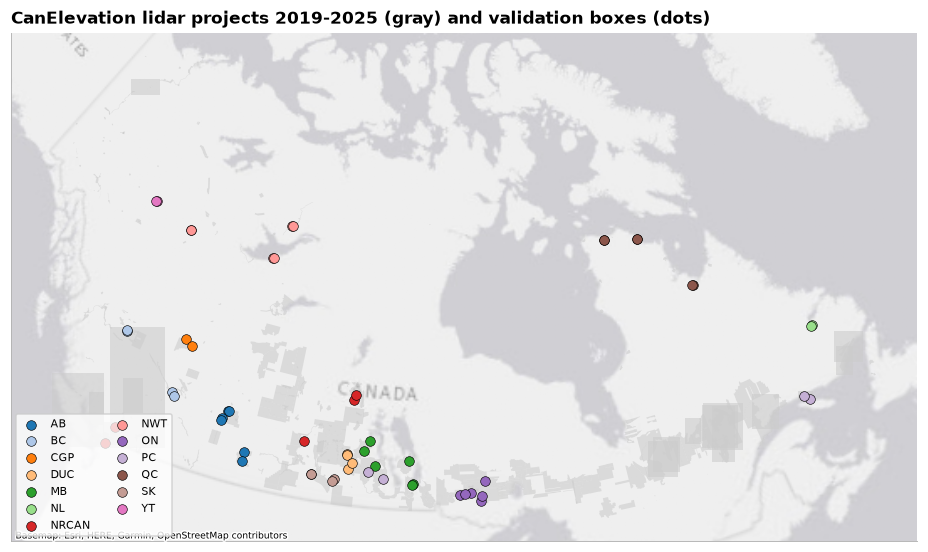

In [3]:
# Map: selected boxes by province / territory (Canada Lambert, ESRI Light Gray basemap)
CRS = 3979
fig, ax = plt.subplots(figsize=(12, 6))
proj.to_crs(CRS).plot(ax=ax, color="0.8", lw=0, alpha=0.6, zorder=2)
cmap = plt.get_cmap("tab20")
for i, (p, g) in enumerate(boxes.groupby("prefix")):
    c = g.to_crs(CRS).geometry.centroid
    ax.scatter(c.x, c.y, s=40, color=cmap(i % 20), edgecolor="k", lw=0.4, zorder=4, label=p)
ps.add_basemap(ax, CRS); ps.map_axes(ax, "CanElevation lidar projects 2019-2025 (gray) and validation boxes (dots)")
ax.legend(ncol=2, loc="lower left", frameon=True, fontsize=7)
fig.savefig(FIG / "10_canelevation_map.png")

## 2 · Canopy height models for the boxes, and ICESat-2 photons over them

**What happens, per box:** (1) read the DSM and DTM windows from the remote COGs and write a local 1 m canopy height model;
(2) find the ATL03 v007 granules of June–September of the lidar year crossing the box and fetch every photon in it, plus the
current v7 30 m PhoREAL segments. Both are cached in the shared work folder.

In [4]:
sliderule = ipl.sliderule_init()
log = []
for r in boxes.itertuples():
    rec = {"box_id": r.box_id}
    try:
        chm = ref.canelevation_chm(r.dsm, r.dtm, r.geometry, CE / "chm" / f"{r.box_id}.tif")
        rec["chm"] = chm
        if chm is None:
            rec["status"] = "no lidar data in box"; log.append(rec); continue
        fn, fpr = CE / "photons" / f"{r.box_id}.parquet", CE / "photons" / f"{r.box_id}_phoreal.parquet"
        if fn.exists():
            rec["status"] = "cached"; log.append(rec); continue
        grs = ipl.granules_from_cmr(r.geometry, [r.year], cfg["icesat2"]["months"], release=cfg["icesat2"]["release"])
        if not grs:
            rec["status"] = "no granules"; log.append(rec); continue
        ph = ipl.fetch_photons(r.geometry, grs, cfg)
        if not len(ph):
            rec["status"] = "no photons"; log.append(rec); continue
        ipl.write_parquet(ph.assign(box_id=r.box_id, prefix=r.prefix), fn, ipl.provenance(cfg, box_id=r.box_id, granules=grs))
        pr = ipl.fetch_phoreal(r.geometry, grs, cfg)
        if len(pr):
            ipl.write_parquet(pr, fpr, ipl.provenance(cfg, box_id=r.box_id))
        rec.update({"status": "fetched", "granules": len(grs), "photons": len(ph), "tracks": ph.track_id.nunique()})
    except Exception as e:
        rec["status"] = f"error: {type(e).__name__}: {str(e)[:120]}"
    log.append(rec)
log = pd.DataFrame(log); log.to_csv(OUT / "fetch_log.csv", index=False)
log.status.str.split(":").str[0].value_counts()

Alert <-7>: Failure on resource ATL03_20220601194754_10801506_007_01.h5 beam gt1r: H5Coro::Future read failure on gt1r/land_segments/segment_snowcover


Alert <-1>: Failed to send data in ATL03_20220601194754_10801506_007_01.h5: invalid dataframe


Alert <-7>: Failure on resource ATL03_20220601194754_10801506_007_01.h5 beam gt1l: H5Coro::Future read failure on gt1l/land_segments/segment_snowcover


Alert <-1>: Failed to send data in ATL03_20220601194754_10801506_007_01.h5: invalid dataframe


Alert <-7>: Failure on resource ATL03_20220601194754_10801506_007_01.h5 beam gt2r: H5Coro::Future read failure on gt2r/land_segments/segment_snowcover


...

(dataframe.lua:210) <AppServer.3474> produced an empty dataframe


(dataframe.lua:210) <AppServer.41> produced an empty dataframe


(dataframe.lua:210) <AppServer.46> produced an empty dataframe


(dataframe.lua:210) <AppServer.3416> produced an empty dataframe


status
fetched                 48
no photons               5
no lidar data in box     4
Name: count, dtype: int64

## 3 · Segments for every version, and the lidar reference height in each footprint

In [5]:
fn = OUT / "segments_canelevation.parquet"
if fn.exists():
    segs = gpd.read_parquet(fn)
else:
    parts = []
    ok = log[log.status.isin(["fetched", "cached"])]
    for r in boxes[boxes.box_id.isin(ok.box_id)].itertuples():
        try:
            ph = gpd.read_parquet(CE / "photons" / f"{r.box_id}.parquet")
            fpr = CE / "photons" / f"{r.box_id}_phoreal.parquet"
            pr = gpd.read_parquet(fpr) if fpr.exists() else None
            s = val.segments_all_versions(ph, CFGS, cfg, pr)
            fps = ref.segment_footprints(s, cfg["validation"]["segment_footprint_width_m"])
            a = ref.als_segment_metrics(fps, [str(CE / "chm" / f"{r.box_id}.tif")], 0.0, 0.0, percentiles=(90, 95, 98, 100))
            a = gpd.GeoDataFrame(a, crs=fps.crs).to_crs(4326)
            parts.append(a.assign(box_id=r.box_id, prefix=r.prefix, lidar_year=r.year, lidar_month=r.month, leaf_on=r.leaf_on))
        except Exception as e:
            print(r.box_id, "failed:", type(e).__name__, str(e)[:150])
    segs = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)
    ipl.write_parquet(segs, fn, ipl.provenance(cfg, configs={k: c["config_sha1"] for k, c in CFGS.items()}))
segs = segs[segs.als_n > 0].copy()
segs["light"] = np.where(segs.solar_elevation > 0, "day", "night")
segs["beam"] = np.where(segs.strong, "strong", "weak")
segs["region"] = segs.prefix
segs.groupby("region").agg(segments=("seg", "size"), boxes=("box_id", "nunique"), lidar_rh98_median=("als_rh98", "median"),
                           leaf_on=("leaf_on", "mean"), day_share=("light", lambda s: (s == "day").mean())).round(2)

NL-Churchill_2019-1m_0 failed: ValueError No objects to concatenate


,segments,boxes,lidar_rh98_median,leaf_on,day_share
region,,,,,
AB,2313,5,0.24,0.06,0.60
BC,443,4,9.76,0.83,1.00
CGP,714,2,0.05,1.00,0.61
DUC,1506,4,0.07,0.00,0.77
MB,1109,4,0.03,0.17,0.90
NL,197,1,2.70,1.00,1.00
NRCAN,1061,3,5.19,0.75,0.00
NWT,1513,6,10.18,0.59,0.75
ON,1607,6,13.01,0.26,0.68


## 4 · Results by reference height class and province / territory (common segments)

coverage (share of segments with a height)


,current v7 30 m,ATL08 classes → our 30 m (check),v0.2,v0.3
region,,,,
AB,0.98,0.82,0.67,0.67
BC,0.86,0.78,0.59,0.59
CGP,0.95,0.59,0.57,0.57
DUC,0.95,0.71,0.63,0.63
MB,0.98,0.61,0.72,0.72
NL,0.89,0.57,0.73,0.73
NRCAN,0.99,0.76,0.61,0.61
NWT,0.93,0.80,0.63,0.63
ON,0.97,0.85,0.52,0.52


bias  \
version                       ATL08 classes → our 30 m (check)   
region      height_class                                         
AB          0-1 m                                         2.87   
            1-2 m                                         3.73   
            10-15 m                                      -3.07   
            15-20 m                                      -3.20   
            2-5 m                                         0.45   
...                                                        ...   
all regions 2-5 m                                         0.44   
            20+ m                                        -3.54   
            5-10 m                                       -0.94   
            all                                           0.20   
            spurious_veg_rate                             0.32   

                                                           \
version                       current v7 30 m  v0.2  v0.3   
region      height_class                                    
AB          0-1 m                        2.46  1.31  1.15   
            1-2 m                        3.35  3.12  2.69   
            10-15 m                     -3.78 -3.60 -3.92   
            15-20 m                     -4.06 -3.18 -3.32   
            2-5 m                        0.76 -0.43 -0.70   
...                                       ...   ...   ...   
all regions 2-5 m                        0.47 -0.02 -0.26   
            20+ m                       -5.21 -3.20 -3.35   
            5-10 m                      -0.88 -0.86 -1.18   
            all                         -0.21 -0.46 -0.65   
            spurious_veg_rate            0.30  0.11  0.09   

                                                             n  \
version                       ATL08 classes → our 30 m (check)   
region      height_class                                         
AB          0-1 m                                        818.0   
            1-2 m                                         61.0   
            10-15 m                                       83.0   
            15-20 m                                       61.0   
            2-5 m                                        124.0   
...                                                        ...   
all regions 2-5 m                                        758.0   
            20+ m                                        511.0   
            5-10 m                                      1025.0   
            all                                         6615.0   
            spurious_veg_rate                           2871.0   

                                                               
version                       current v7 30 m    v0.2    v0.3  
region      height_class                                       
AB          0-1 m                       818.0   818.0   818.0  
            1-2 m                        61.0    61.0    61.0  
            10-15 m                      83.0    83.0    83.0  
            15-20 m                      61.0    61.0    61.0  
            2-5 m                       124.0   124.0   124.0  
...                                       ...     ...     ...  
all regions 2-5 m                       758.0   758.0   758.0  
            20+ m                       511.0   511.0   511.0  
            5-10 m                     1025.0  1025.0  1025.0  
            all                        6615.0  6615.0  6615.0  
            spurious_veg_rate          2871.0  2871.0  2871.0  

[126 rows x 8 columns]

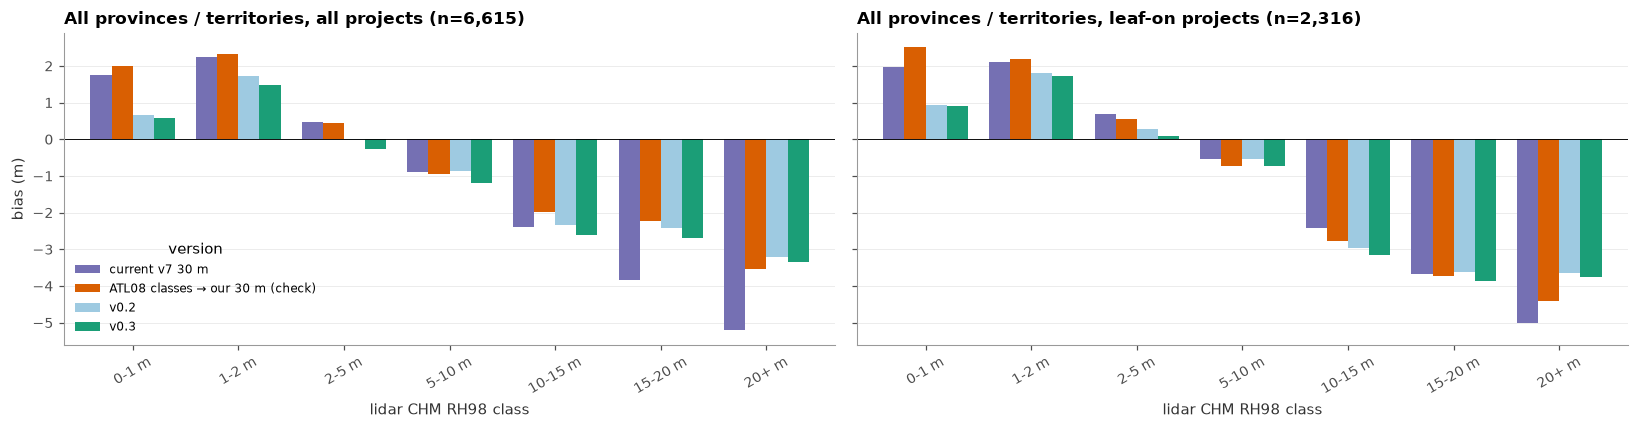

In [6]:
VERS = {"current v7 30 m": "h_canopy_phoreal", "ATL08 classes → our 30 m (check)": "h_canopy_atl08",
        "v0.2": "h_canopy_v02", "v0.3": "h_canopy_v03"}
VCOL = {"current v7 30 m": val.SCHEME_COLORS[val.LABEL_CURRENT], "ATL08 classes → our 30 m (check)": val.SCHEME_COLORS[val.LABEL_CHECK],
        "v0.2": "#9ecae1", "v0.3": val.SCHEME_COLORS[val.LABEL_NEW]}
REF = "als_rh98"
edges = cfg["validation"]["height_classes_m"]
cov = pd.DataFrame({k: segs.groupby("region")[c].apply(lambda s: s.notna().mean()) for k, c in VERS.items()}).round(2)
print("coverage (share of segments with a height)"); display(cov)
common = segs.dropna(subset=list(VERS.values()) + [REF])
rows = []
for (sub, g0) in [("all projects", common), ("leaf-on projects", common[common.leaf_on])]:
    for reg, g in list(g0.groupby("region")) + [("all regions", g0)]:
        for k, c in VERS.items():
            rows.append(val.metrics_by_height_class(g[c], g[REF], edges, cfg["validation"]["spurious_veg"]).assign(region=reg, version=k, subset=sub))
res = pd.concat(rows).reset_index(names="height_class")
res.to_csv(OUT / "canelevation_by_class_region_common.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, sub in zip(axes, ["all projects", "leaf-on projects"]):
    tt = res[(res.region == "all regions") & (res.subset == sub) & ~res.height_class.isin(["all", "spurious_veg_rate"])]
    pv = tt.pivot(index="height_class", columns="version", values="bias").reindex(val.height_class_labels(edges))[list(VERS)]
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[VCOL[c] for c in pv.columns], legend=(sub == "all projects"))
    ax.axhline(0, c="k", lw=0.6); ax.grid(axis="x", visible=False); ax.set_xlabel("lidar CHM RH98 class"); ax.set_ylabel("bias (m)")
    ax.set_title(f"All provinces / territories, {sub} (n={int(tt[tt.version == 'v0.3'].n.sum()):,})")
fig.tight_layout(); fig.savefig(FIG / "10_canelevation_bias.png")
res[res.subset == "all projects"].pivot_table(index=["region", "height_class"], columns="version", values=["n", "bias"]).round(2)

In [7]:
# Tall-forest acceptance per region (classes >= 10 m with >= 10 segments) and spurious vegetation
tall = [c for c in val.height_class_labels(edges) if int(c.split("-")[0].split("+")[0]) >= 10]
acc = []
for reg in sorted(common.region.unique()) + ["all regions"]:
    for cl in tall:
        t = res[(res.subset == "all projects") & (res.region == reg) & (res.height_class == cl)].set_index("version")
        if t.empty or t.loc["current v7 30 m", "n"] < 10:
            continue
        b7 = t.loc["current v7 30 m", "bias"]
        acc.append({"region": reg, "class": cl, "n": int(t.loc["v0.3", "n"]), "bias current v7": b7,
                    **{f"bias {v}": t.loc[v, "bias"] for v in ("v0.2", "v0.3")},
                    **{f"{v} passes": bool(t.loc[v, "bias"] >= b7) for v in ("v0.2", "v0.3")}})
acc = pd.DataFrame(acc); acc.to_csv(OUT / "canelevation_tall_acceptance.csv", index=False)
spur = res[(res.subset == "all projects") & (res.height_class == "spurious_veg_rate")].pivot(index="region", columns="version", values="bias")[list(VERS)].round(3)
display(spur.rename_axis(None, axis=1))
acc.round(2)

,current v7 30 m,ATL08 classes → our 30 m (check),v0.2,v0.3
region,,,,
AB,0.446,0.490,0.199,0.183
BC,1.000,1.000,1.000,1.000
CGP,0.422,0.454,0.070,0.065
DUC,0.233,0.187,0.091,0.063
MB,0.275,0.273,0.046,0.042
NL,0.053,0.211,0.000,0.000
NRCAN,0.118,0.092,0.039,0.039
NWT,0.143,0.857,0.000,0.000
ON,0.211,0.474,0.026,0.026


,region,class,n,bias current v7,bias v0.2,bias v0.3,v0.2 passes,v0.3 passes
0,AB,10-15 m,83,-3.78,-3.60,-3.92,True,False
1,AB,15-20 m,61,-4.06,-3.18,-3.32,True,True
2,AB,20+ m,49,-6.00,-3.00,-3.06,True,True
3,BC,10-15 m,34,0.18,1.49,1.49,True,True
4,BC,15-20 m,40,-4.83,-0.71,-0.71,True,True
5,BC,20+ m,43,-13.66,-8.15,-8.15,True,True
6,CGP,10-15 m,11,-3.53,-1.62,-2.52,True,True
7,CGP,15-20 m,13,-4.64,-4.85,-6.02,False,False
8,DUC,10-15 m,16,-5.13,-2.18,-2.82,True,True
9,NL,10-15 m,11,-8.90,-7.68,-7.68,True,True


n                          \
version        ATL08 classes → our 30 m (check) current v7 30 m    v0.2   
stratum                                                                   
day · strong                             3286.0          3286.0  3286.0   
day · weak                               1087.0          1087.0  1087.0   
night · strong                           1794.0          1794.0  1794.0   
night · weak                              448.0           448.0   448.0   

                                                      r                        \
version           v0.3 ATL08 classes → our 30 m (check) current v7 30 m  v0.2   
stratum                                                                         
day · strong    3286.0                             0.89            0.82  0.85   
day · weak      1087.0                             0.53            0.53  0.47   
night · strong  1794.0                             0.88            0.89  0.84   
night · weak     448.0                             0.82            0.80  0.63   

                                                 bias                        \
version         v0.3 ATL08 classes → our 30 m (check) current v7 30 m  v0.2   
stratum                                                                       
day · strong    0.86                             0.24           -0.51  0.38   
day · weak      0.47                             1.91            0.54 -1.07   
night · strong  0.84                            -0.57            0.07 -1.12   
night · weak    0.63                            -1.11           -0.91 -2.56   

                                                 rmse                        \
version         v0.3 ATL08 classes → our 30 m (check) current v7 30 m  v0.2   
stratum                                                                       
day · strong    0.04                             3.87            4.86  4.68   
day · weak     -1.18                             4.87            4.08  4.69   
night · strong -1.12                             3.39            3.26  3.97   
night · weak   -2.56                             3.27            3.31  4.85   

                      
version         v0.3  
stratum               
day · strong    4.46  
day · weak      4.65  
night · strong  3.97  
night · weak    4.85

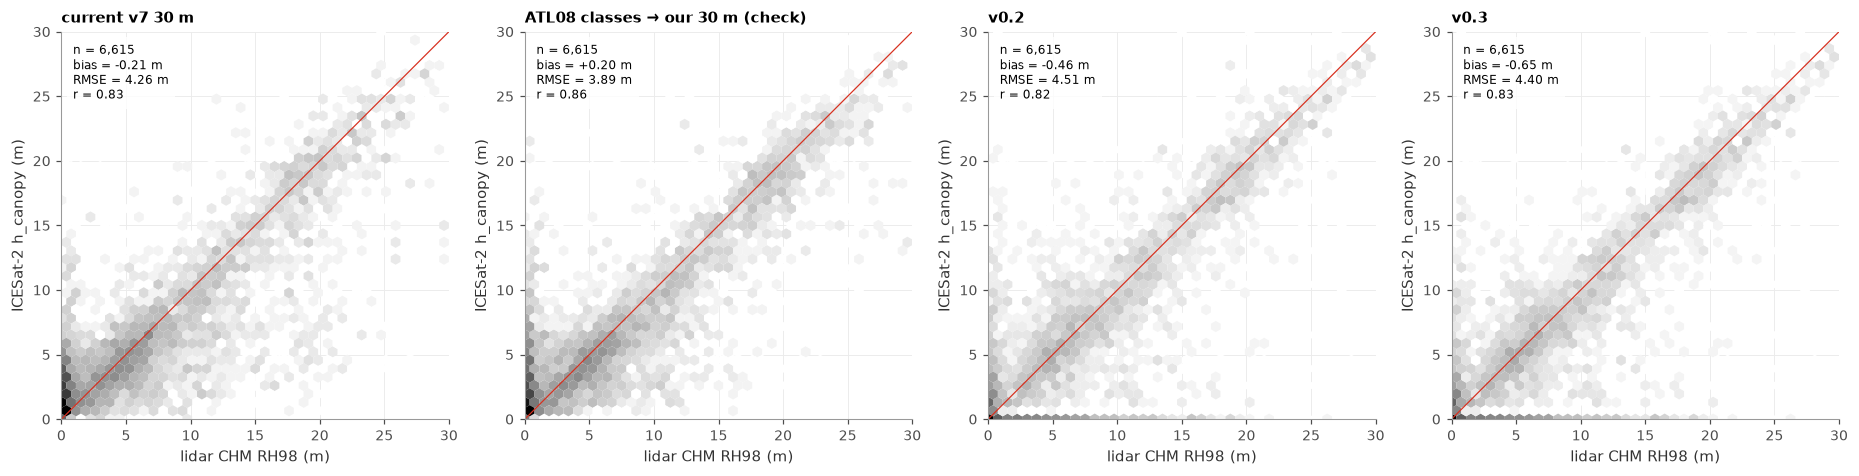

In [8]:
common = common.assign(signal_stratum=common.light + " · " + common.beam)
rows = []
for st, g in common.groupby("signal_stratum"):
    for k, c in VERS.items():
        e = g[c] - g[REF]
        rows.append({"stratum": st, "version": k, "n": len(g), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r": g[[c, REF]].corr().iat[0, 1]})
sig = pd.DataFrame(rows); sig.to_csv(OUT / "canelevation_by_signal.csv", index=False)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
for ax, (k, c) in zip(axes, VERS.items()):
    val.plot_scatter(ax, common[c], common[REF], k, lim=30); ax.set_xlabel("lidar CHM RH98 (m)")
fig.tight_layout(); fig.savefig(FIG / "10_canelevation_scatter.png")
sig.pivot(index="stratum", columns="version", values=["n", "r", "bias", "rmse"]).round(2)

## Results
Summarise after review: per province / territory and overall, tall-forest acceptance, spurious vegetation and bias by
height class for v0.2 and v0.3 vs the current v7 30 m; the leaf-on subset; differences by day/night and beam.